# Model and threshold selection under a risk scenario

This notebook executes the development protocol for selecting a model and a threshold, consuming the tuned hyperparameters from Notebook 5a when the tuning contract is available. The official test remains reserved for one pre-specified final evaluation. Executable logic lives in `src/threshold_selection.py`; the notebook presents the contract and evidence.

## 1. Preparation and evidence generation

The pipeline separates fitting, calibration, and selection roles inside the official training set. Predictor signatures are treated as groups so identical observations cannot cross those partitions.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from adult_data import load_adult
from group_audit_plots import build_group_audit_svgs
from threshold_plots import build_threshold_metric_svgs
from threshold_selection import write_threshold_selection_outputs

data = load_adult(ROOT / 'data' / 'raw' / 'adult_uci')
selection_dir = ROOT / 'data' / 'processed' / 'selection'
tuning_contract_path = ROOT / 'data' / 'processed' / 'tuning' / 'hgb_tuning_contract.json'
tuned_model_params = None
if tuning_contract_path.exists():
    tuned_model_params = json.loads(tuning_contract_path.read_text(encoding='utf-8'))['selected_params']
outputs = write_threshold_selection_outputs(
    data, selection_dir, tuned_model_params=tuned_model_params
)
outputs

{'model_metrics': WindowsPath('D:/Projetos/ModelRisk_ResponsibleML/data/processed/selection/selection_model_metrics.csv'),
 'threshold_metrics': WindowsPath('D:/Projetos/ModelRisk_ResponsibleML/data/processed/selection/selection_threshold_metrics.csv'),
 'group_metrics': WindowsPath('D:/Projetos/ModelRisk_ResponsibleML/data/processed/selection/selection_group_metrics.csv'),
 'contract': WindowsPath('D:/Projetos/ModelRisk_ResponsibleML/data/processed/selection/threshold_selection_contract.json')}

## 2. Decision contract

The contract records the risk scenario, partitions, selection rule, and the fact that the official test was not used. The recall and precision floors are provisional development parameters, not validated business requirements.

In [2]:
contract = json.loads((selection_dir / 'threshold_selection_contract.json').read_text(encoding='utf-8'))
display(pd.Series(contract, name='value').to_frame())

,value
protocol_version,mvp-1
official_train_rows,32561
fit_rows,19537
calibration_rows,6512
selection_rows,6512
official_test_rows_reserved,16281
group_aware_split,True
group_signature,model_predictor_columns_with_missing_marker
duplicate_policy,group_identical_predictor_signatures_across_de...
official_test_overlap_diagnostic_only,True


### Insights:
The contract makes the development status explicit: `test_used=false` and `final_test_evaluation_pending=true`. The group-aware split reduces the risk that duplicate predictor signatures cross blocks, but it does not replace the final decision about the dataset duplicate policy.

## 3. Model selection with out-of-fold predictions

The question is which candidate has the strongest development performance without selecting the model from predictions made on the same rows used to fit it. `hist_gradient_boosting` enters this comparison with the configuration selected in Notebook 5a; the other candidates remain baselines. All candidates are compared with out-of-fold predictions inside the `fit` block; PR-AUC is the first criterion, followed by ROC-AUC and Brier for ties.

In [3]:
model_metrics = pd.read_csv(selection_dir / 'selection_model_metrics.csv')
display(model_metrics.round(4))

,model,threshold,roc_auc,pr_auc,brier,precision,recall_tpr,f1,selection_rate
0,hist_gradient_boosting,0.5,0.9231,0.8189,0.0912,0.7801,0.6317,0.6981,0.1950
1,random_forest,0.5,0.9148,0.7939,0.0975,0.7736,0.6021,0.6772,0.1874
2,logistic_regression,0.5,0.9047,0.7642,0.1028,0.7387,0.5985,0.6613,0.1951
3,dummy_prior,0.5,0.4999,0.2408,0.1828,0.0000,0.0000,0.0000,0.0000


### Insights:
After hyperparameter tuning, `hist_gradient_boosting` still leads the OOF comparison in the fitting block. This justifies its provisional selection for threshold analysis, but it is not final performance: all decisions used development data only.

## 4. Probability calibration and threshold selection

The selected model, with tuned hyperparameters, is fitted on `fit`. A sigmoid calibrator is fitted separately on `calibration`, and the threshold grid is evaluated on `selection`. Estimator tuning, calibration, and threshold choice therefore remain separate roles. Optuna is not used in this version; the search was a small explicit grid.

In [4]:
threshold_metrics = pd.read_csv(selection_dir / 'selection_threshold_metrics.csv')
selected_model = contract['selected_model']
selected_threshold = contract['selected_threshold']
candidate_metrics = threshold_metrics.query('model == @selected_model').sort_values('threshold')
display(candidate_metrics.round(4))

,model,threshold,roc_auc,pr_auc,brier,precision,recall_tpr,f1,selection_rate
0,hist_gradient_boosting,0.10,0.9249,0.821,0.0901,0.4840,0.9458,0.6403,0.4705
1,hist_gradient_boosting,0.11,0.9249,0.821,0.0901,0.4956,0.9426,0.6497,0.4579
2,hist_gradient_boosting,0.12,0.9249,0.821,0.0901,0.5081,0.9375,0.6590,0.4443
3,hist_gradient_boosting,0.13,0.9249,0.821,0.0901,0.5171,0.9330,0.6655,0.4344
4,hist_gradient_boosting,0.14,0.9249,0.821,0.0901,0.5258,0.9292,0.6716,0.4255
...,...,...,...,...,...,...,...,...,...
76,hist_gradient_boosting,0.86,0.9249,0.821,0.0901,0.9701,0.2895,0.4460,0.0719
77,hist_gradient_boosting,0.87,0.9249,0.821,0.0901,0.9715,0.2825,0.4377,0.0700
78,hist_gradient_boosting,0.88,0.9249,0.821,0.0901,0.9770,0.2710,0.4244,0.0668
79,hist_gradient_boosting,0.89,0.9249,0.821,0.0901,0.9807,0.2589,0.4097,0.0636


### Metric evolution with the threshold

The plots below show the metrics that vary with the threshold: precision, recall/TPR, F1, and selection rate. ROC-AUC, PR-AUC, and Brier evaluate the probabilities and therefore remain constant in this table.

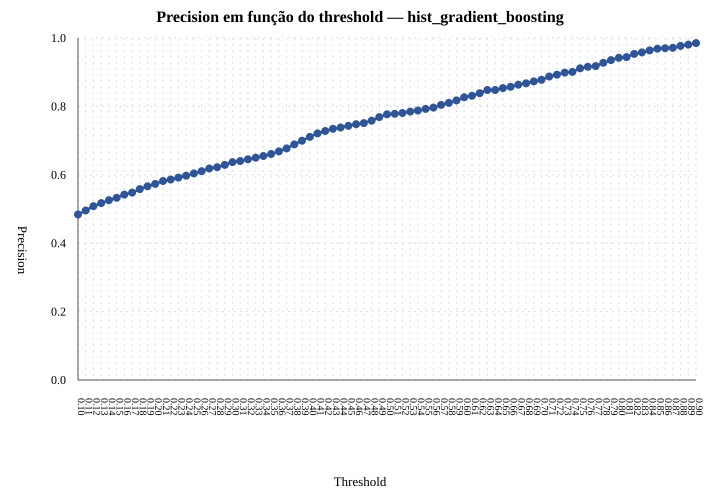

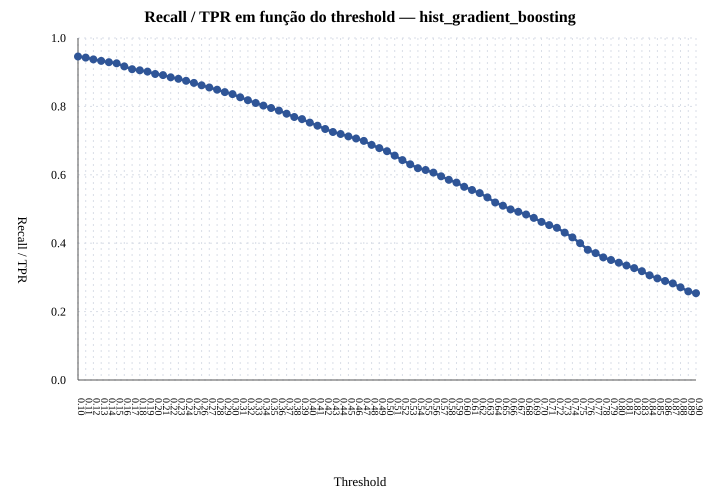

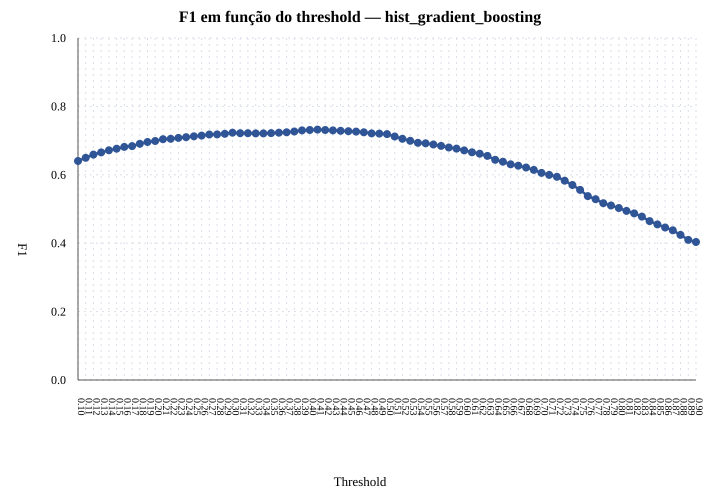

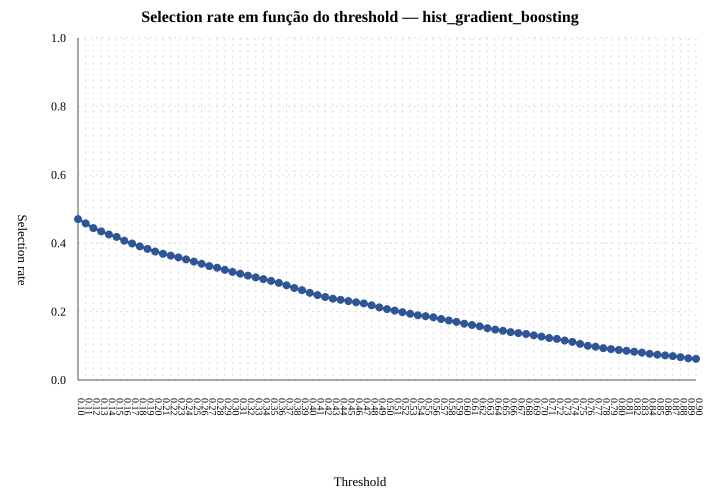

In [5]:
metric_labels = {
    'precision': 'Precision',
    'recall_tpr': 'Recall / TPR',
    'f1': 'F1',
    'selection_rate': 'Selection rate',
}
threshold_svgs = build_threshold_metric_svgs(
    candidate_metrics, metric_labels, selected_model
)
for svg in threshold_svgs.values():
    display(SVG(svg))

### Insights:
The original reference gate requires recall ≥ 0.80 and precision ≥ 0.65. For this hypothetical portfolio, the approved exception activates recall ≥ 0.79 and precision ≥ 0.64. With the 0.01 grid, the lowest eligible threshold is 0.32, with recall approximately 0.815 and precision approximately 0.643. This is an exploratory winner, not production approval.

## 5. Recorded decision and group audit

The choice must be read together with differences by sex and race. Wilson intervals describe uncertainty for rates within the selection block; they do not prove equality between groups or generalization to the official test.

In [6]:
selected_row = candidate_metrics.query('threshold == @selected_threshold')
display(selected_row.round(4))

group_metrics = pd.read_csv(selection_dir / 'selection_group_metrics.csv')
selected_groups = group_metrics.query(
    'model == @selected_model and threshold == @selected_threshold'
).sort_values(['audit_column', 'metric', 'estimate'])
display(selected_groups.round(4))

,model,threshold,roc_auc,pr_auc,brier,precision,recall_tpr,f1,selection_rate
21,hist_gradient_boosting,0.31,0.9249,0.821,0.0901,0.6403,0.8265,0.7216,0.3108


,model,threshold,audit_column,group,count,denominator,metric,estimate,ci_low,ci_high,low_support
28,hist_gradient_boosting,0.31,race,Other,44,3,fnr,0.0000,0.0000,0.5615,True
18,hist_gradient_boosting,0.31,race,Asian-Pac-Islander,219,61,fnr,0.1639,0.0916,0.2761,False
33,hist_gradient_boosting,0.31,race,White,5524,1406,fnr,0.1728,0.1540,0.1935,False
23,hist_gradient_boosting,0.31,race,Black,663,94,fnr,0.1915,0.1247,0.2825,False
13,hist_gradient_boosting,0.31,race,Amer-Indian-Eskimo,62,4,fnr,0.2500,0.0456,0.6994,True
...,...,...,...,...,...,...,...,...,...,...,...
81,hist_gradient_boosting,0.31,sex_race,Male × White,3758,1208,tpr,0.8394,0.8176,0.8590,False
66,hist_gradient_boosting,0.31,sex_race,Male × Asian-Pac-Islander,153,56,tpr,0.8750,0.7637,0.9381,False
36,hist_gradient_boosting,0.31,sex_race,Female × Amer-Indian-Eskimo,25,1,tpr,1.0000,0.2065,1.0000,True
51,hist_gradient_boosting,0.31,sex_race,Female × Other,20,2,tpr,1.0000,0.3424,1.0000,True


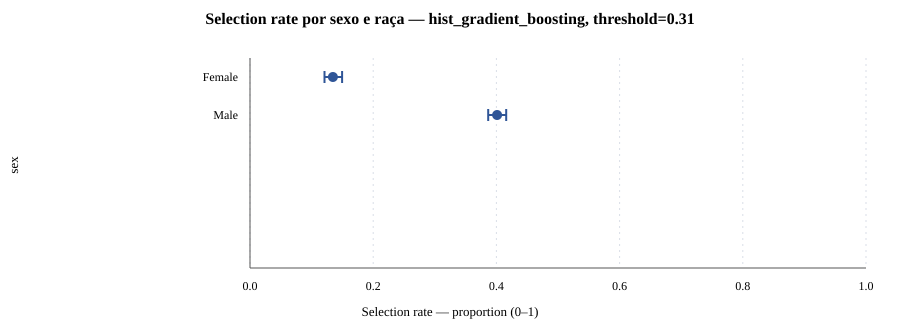

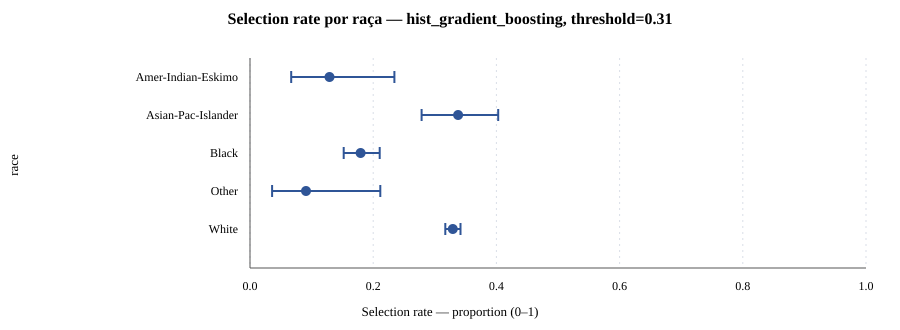

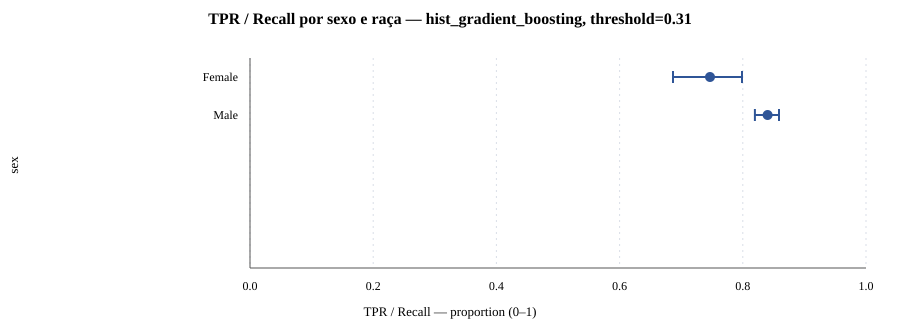

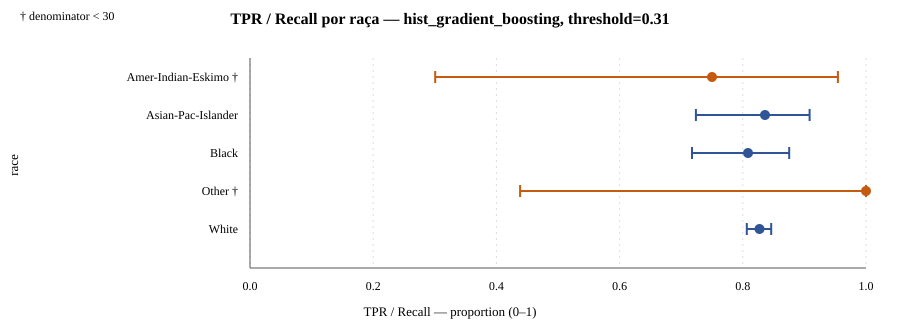

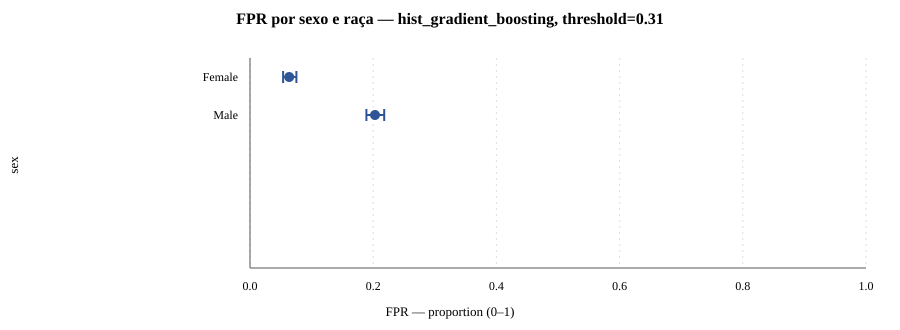

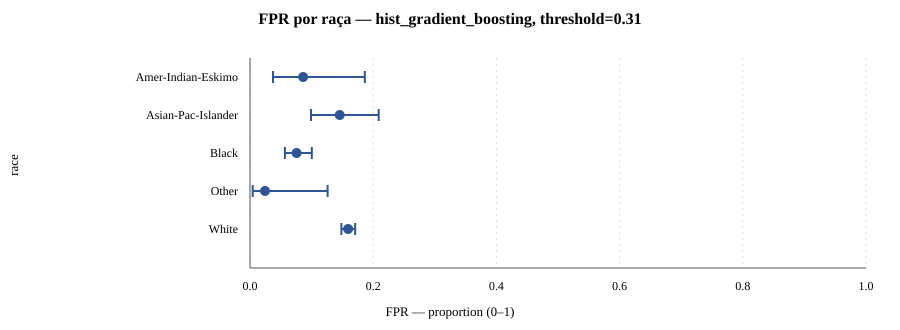

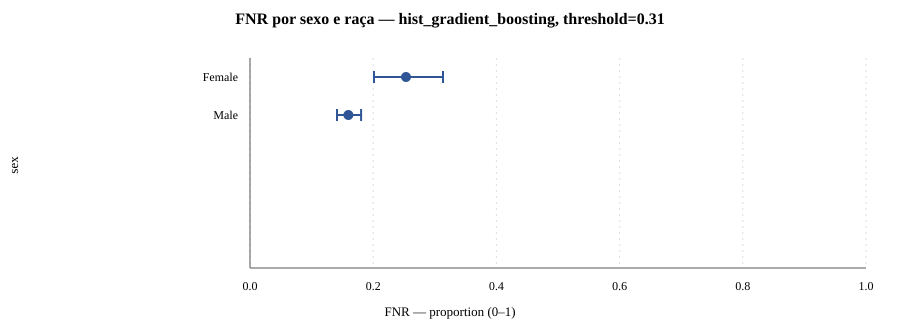

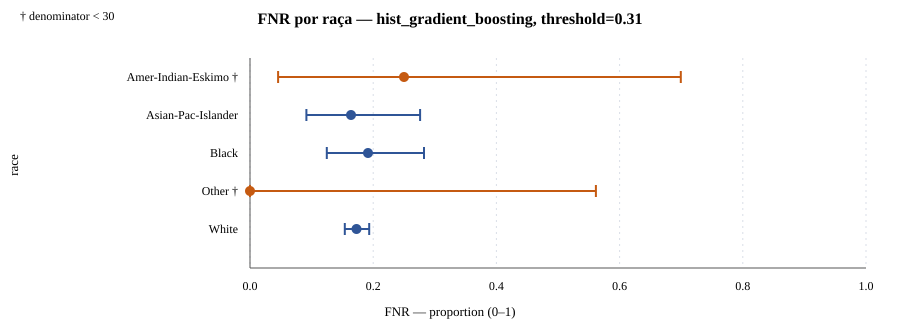

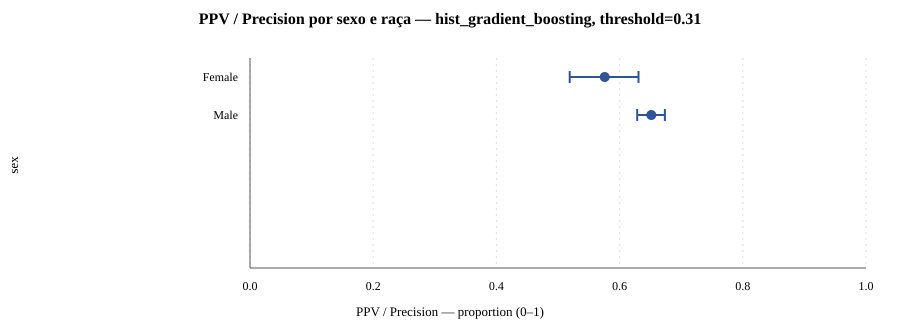

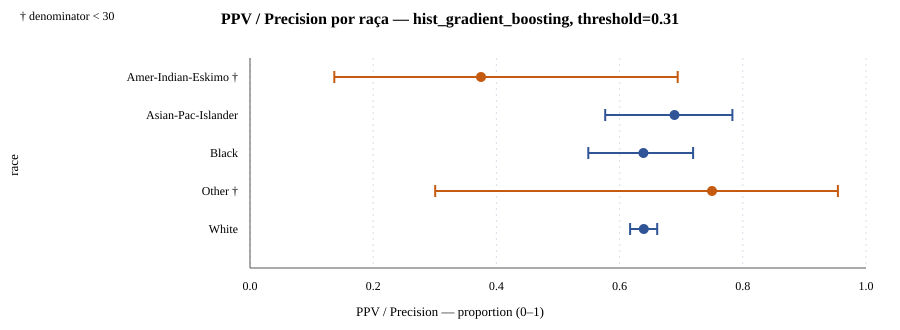

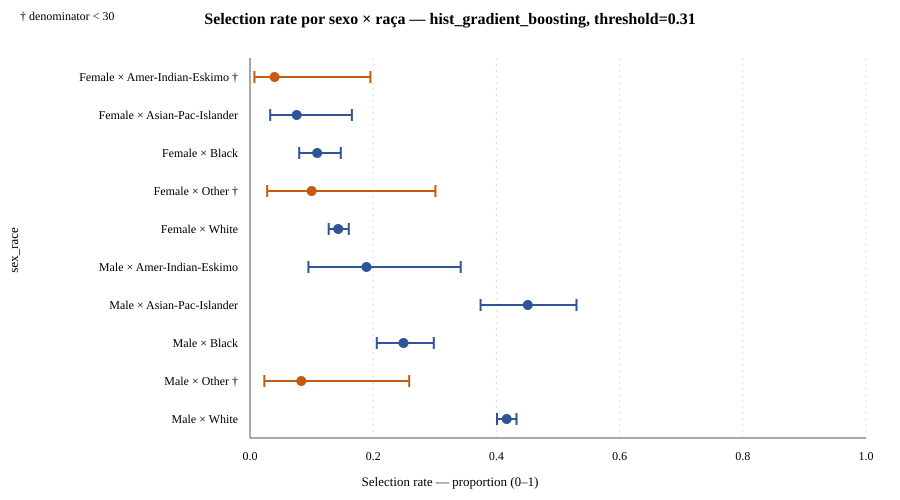

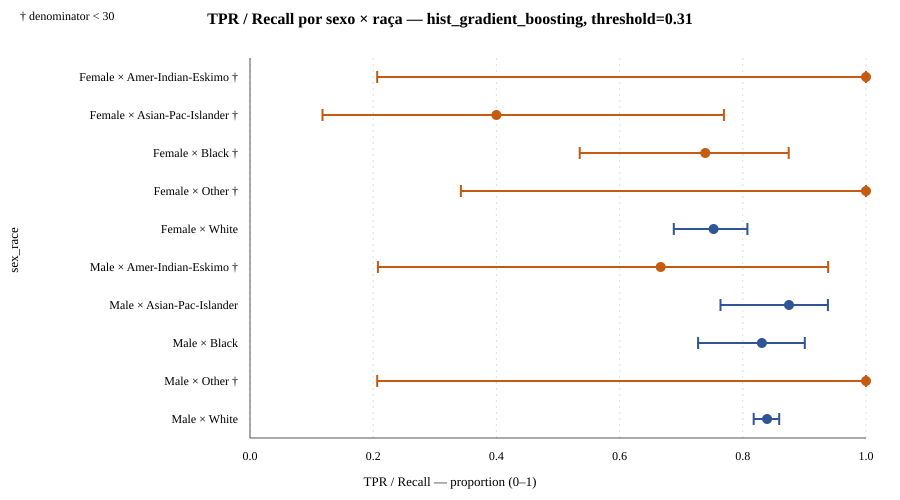

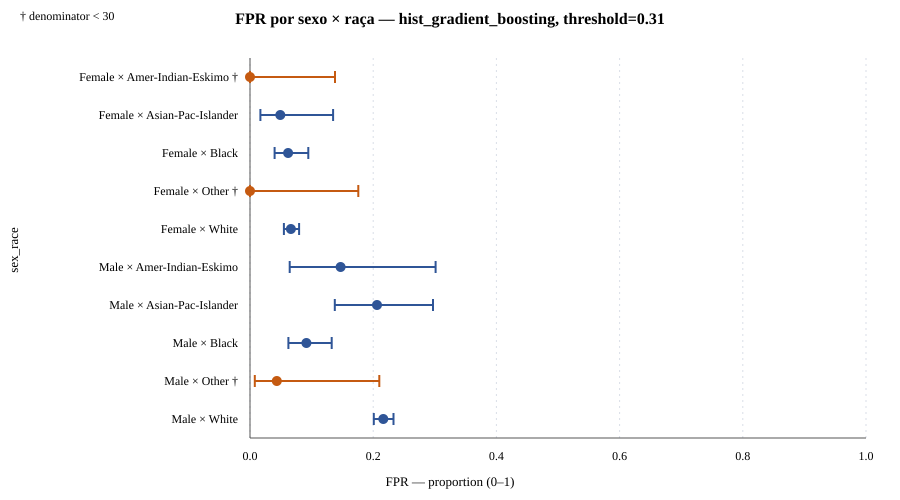

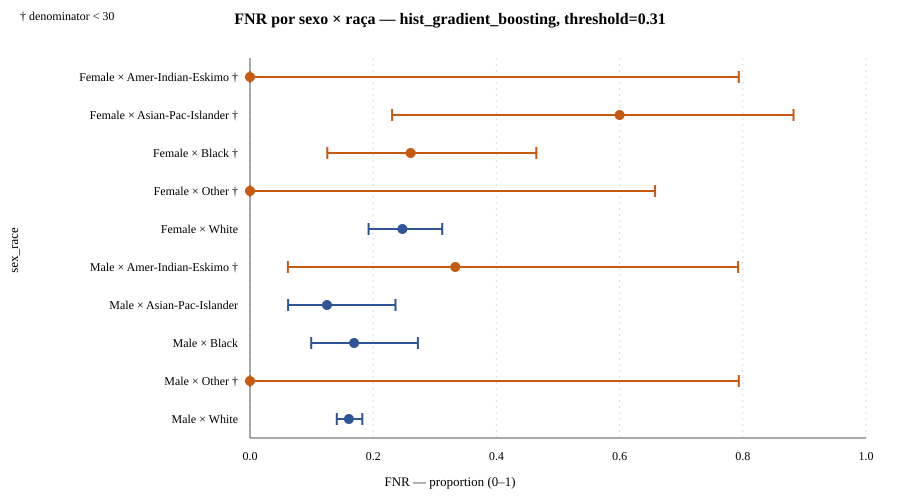

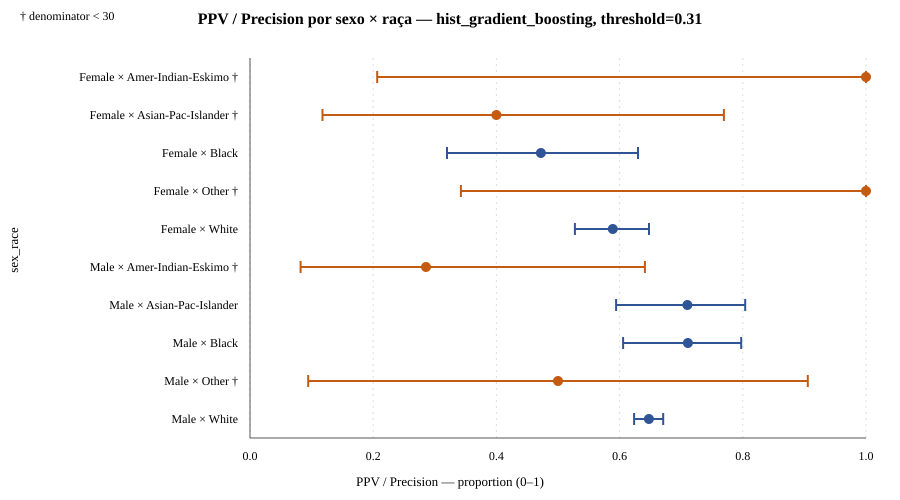

In [7]:
group_labels = {
    'selection_rate': 'Selection rate',
    'tpr': 'TPR / Recall',
    'fpr': 'FPR',
    'fnr': 'FNR',
    'ppv': 'PPV / Precision',
}
group_svgs = build_group_audit_svgs(
    selected_groups, group_labels, selected_model, selected_threshold
)
for svg in group_svgs['marginal'].values():
    display(SVG(svg))
for svg in group_svgs['intersection'].values():
    display(SVG(svg))

### Insights:
The selected threshold changes coverage, precision, and error rates by group at the same time. Groups with small support have wide intervals and should be treated as uncertain evidence, not as a stable ranking. The audit shows what must be reviewed before freezing the decision; it does not support a mitigation claim merely because sex and race were not direct predictors.

## 6. Next step

Before final evaluation, review the risk floors, decide the duplicate policy, and verify the contract. Then use `test_official` once for the pre-specified final metrics, without returning to the selection process.